# 01 — Exploratory Data Analysis
**Vehicle Insurance Claim Fraud Detection** (fraud_oracle, 15,420 claims, 33 columns).

Goals: quantify the class imbalance, understand which raw attributes separate
fraud from clean claims, and hunt for **leakage columns** before any modeling.

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocessing import load_raw

plt.style.use("seaborn-v0_8-whitegrid")
FIG = "figures"
os.makedirs(FIG, exist_ok=True)

df = load_raw()
print(df.shape)
df.head()

(15420, 33)


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


## Class balance — the defining constraint of this problem

Clean: 14,497 | Fraud: 923 | fraud rate: 5.99%


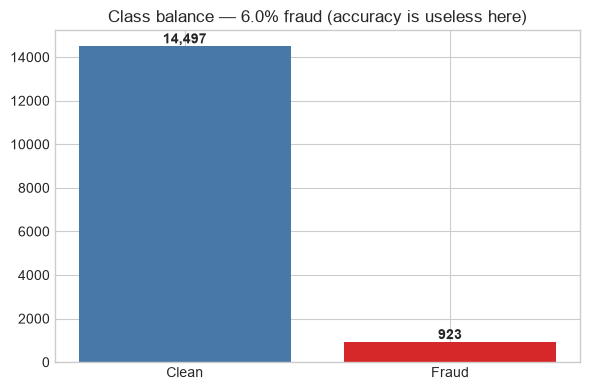

In [2]:
counts = df["FraudFound_P"].value_counts()
rate = df["FraudFound_P"].mean()
print(f"Clean: {counts[0]:,} | Fraud: {counts[1]:,} | fraud rate: {rate:.2%}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Clean", "Fraud"], counts.values, color=["#4878A8", "#D62828"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontweight="bold")
ax.set_title(f"Class balance — {rate:.1%} fraud (accuracy is useless here)")
fig.tight_layout(); fig.savefig(f"{FIG}/eda_class_balance.png", dpi=150)
plt.show()

With ~6% prevalence, a model that never flags anything is 94% "accurate" while
catching zero fraud — every later metric choice follows from this.

## Fraud rate by key categorical attributes

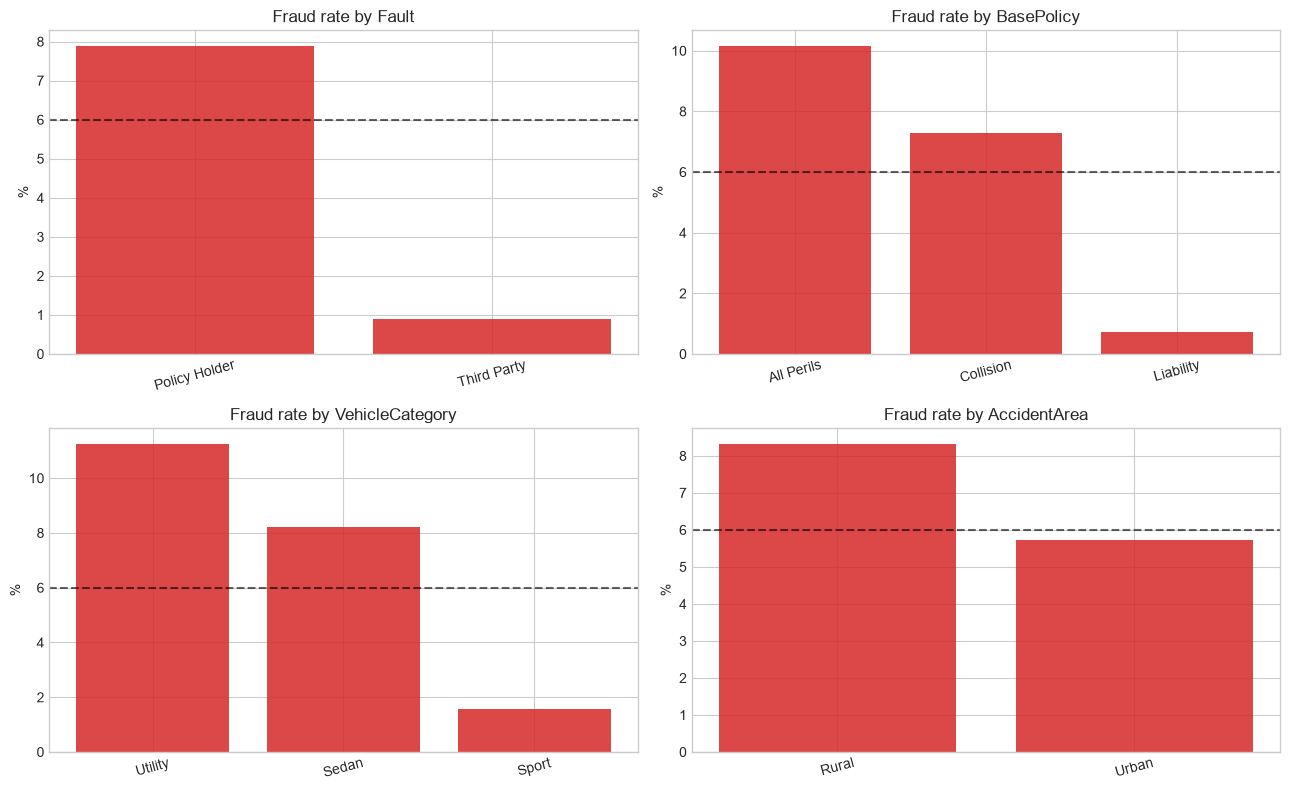

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), ["Fault", "BasePolicy", "VehicleCategory", "AccidentArea"]):
    r = df.groupby(col)["FraudFound_P"].mean().sort_values(ascending=False)
    ax.bar(r.index.astype(str), r.values * 100, color="#D62828", alpha=0.85)
    ax.axhline(df["FraudFound_P"].mean() * 100, ls="--", color="black", alpha=0.6)
    ax.set_title(f"Fraud rate by {col}")
    ax.set_ylabel("%")
    ax.tick_params(axis="x", rotation=15)
fig.tight_layout(); fig.savefig(f"{FIG}/eda_fraud_by_category.png", dpi=150)
plt.show()

`Fault = Policy Holder` and `BasePolicy = All Perils` carry far more fraud than
the base rate — both become important model features later.

## Numeric / ordered distributions by label

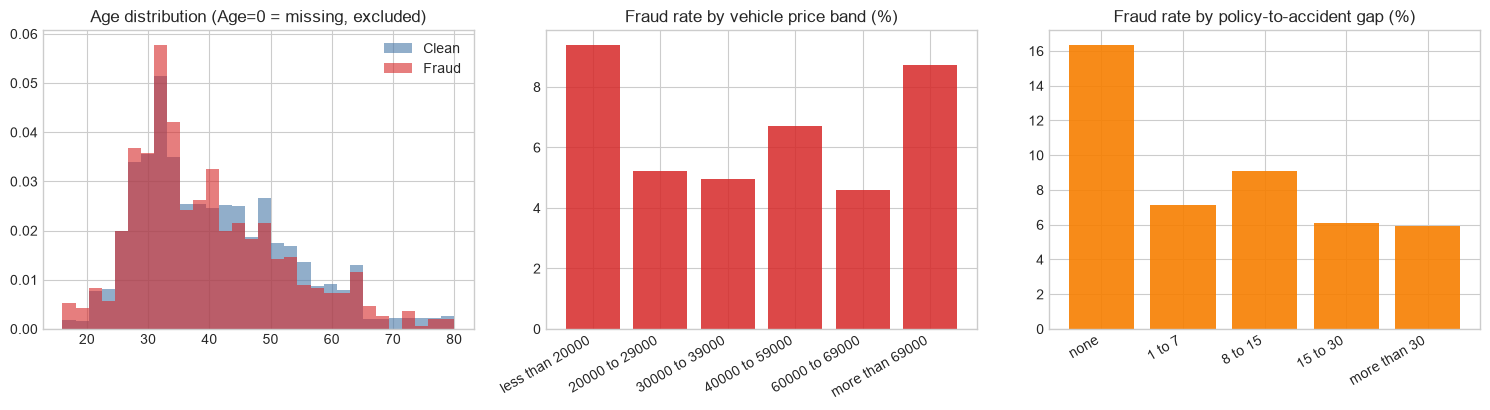

In [4]:
price_order = ["less than 20000", "20000 to 29000", "30000 to 39000",
               "40000 to 59000", "60000 to 69000", "more than 69000"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

age = df[df["Age"] > 0]
for label, color, name in [(0, "#4878A8", "Clean"), (1, "#D62828", "Fraud")]:
    axes[0].hist(age.loc[age["FraudFound_P"] == label, "Age"], bins=30,
                 alpha=0.6, density=True, color=color, label=name)
axes[0].set_title("Age distribution (Age=0 = missing, excluded)"); axes[0].legend()

vp = df.groupby("VehiclePrice")["FraudFound_P"].mean().reindex(price_order) * 100
axes[1].bar(range(len(vp)), vp.values, color="#D62828", alpha=0.85)
axes[1].set_xticks(range(len(vp)), vp.index, rotation=30, ha="right")
axes[1].set_title("Fraud rate by vehicle price band (%)")

gap = df.groupby("Days_Policy_Accident")["FraudFound_P"].mean() * 100
gap = gap.reindex(["none", "1 to 7", "8 to 15", "15 to 30", "more than 30"])
axes[2].bar(range(len(gap)), gap.values, color="#F77F00", alpha=0.9)
axes[2].set_xticks(range(len(gap)), gap.index, rotation=30, ha="right")
axes[2].set_title("Fraud rate by policy-to-accident gap (%)")

fig.tight_layout(); fig.savefig(f"{FIG}/eda_distributions.png", dpi=150)
plt.show()

## Correlation heatmap (ordinal-decoded numerics)

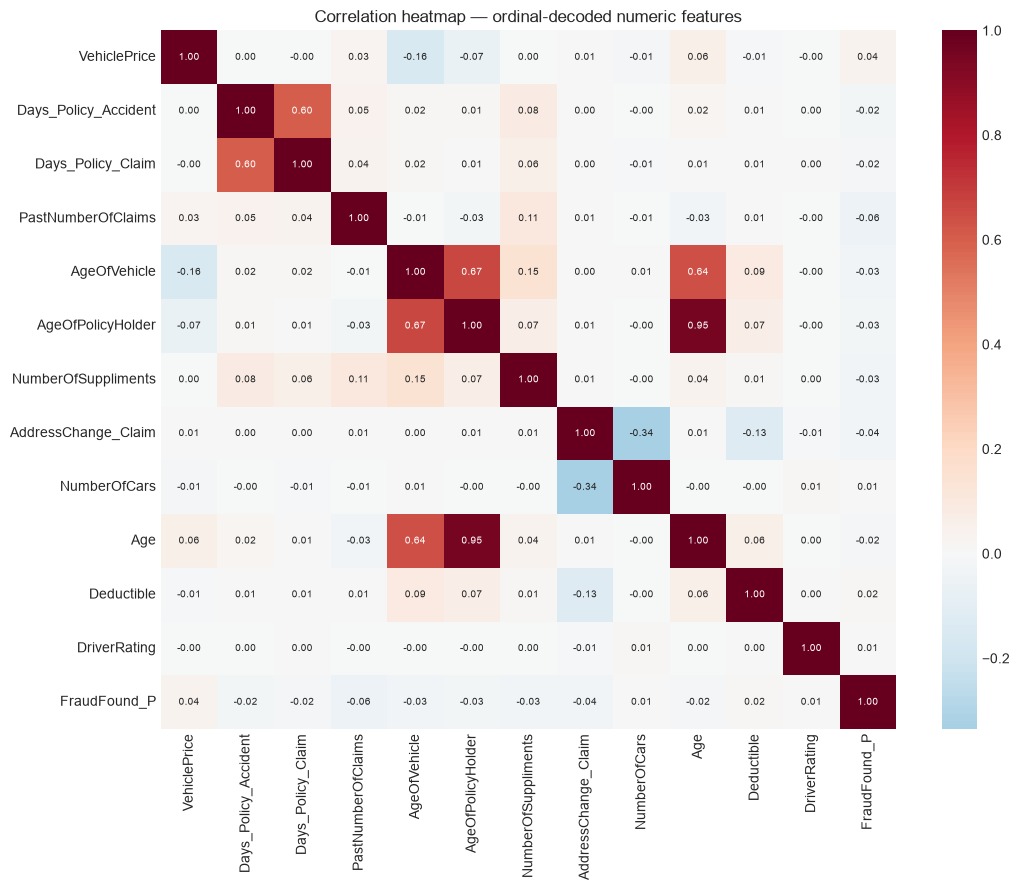

In [5]:
from src.features import ORDINAL_MAPS
num = pd.DataFrame({f"{c}": df[c].map(m) for c, m in ORDINAL_MAPS.items()})
num["Age"] = df["Age"].replace(0, np.nan)
num["Deductible"] = df["Deductible"]
num["DriverRating"] = df["DriverRating"]
num["FraudFound_P"] = df["FraudFound_P"]

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(num.corr(), cmap="RdBu_r", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation heatmap — ordinal-decoded numeric features")
fig.tight_layout(); fig.savefig(f"{FIG}/eda_correlation_heatmap.png", dpi=150)
plt.show()

## Leakage hunt

Two red flags checked explicitly:

1. **`PolicyNumber`** is a perfect 1..15420 row index. Rows are ordered in time,
   so a tree model can split on it and memorize eras — it must be dropped
   (done in `src/preprocessing.py`).
2. **Claimed-date fields** contain a single corrupt `'0'` row — dropped.

No column shows suspicious near-perfect correlation with the label
(max |r| with the target above is modest), so no further leakage drops needed.

In [6]:
print("PolicyNumber is literally the row index:",
      (df['PolicyNumber'] == np.arange(1, len(df) + 1)).all())
print("corrupt claimed-date rows:", (df['DayOfWeekClaimed'] == '0').sum())
print("Age = 0 (missing marker):", (df['Age'] == 0).sum())

PolicyNumber is literally the row index: True
corrupt claimed-date rows: 1
Age = 0 (missing marker): 320
